# 라이브러리 불러오기

In [7]:
# 현재위치 폴더열기
from pathlib import Path
import os
os.startfile(Path.cwd())

In [8]:
# 기본 분석 및 계산용 라이브러리
import pandas as pd
import numpy as np

# 그래프 관련 라이브러리
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.family'] = 'Malgun Gothic'   # 한글 폰트 설정: Windows
plt.rcParams['axes.unicode_minus'] = False      # 마이너스 기호 깨짐 방지

# 데이터 불러오기

In [10]:
# 지난시간 데이터 가져오기
df1 = pd.read_excel('sample_data.xlsx', sheet_name=0)
df2 = pd.read_excel('sample_data.xlsx', sheet_name=1)

df1.shape, df2.shape

((1000, 10), (14, 8))

In [11]:
df1.head(3)

,transaction_id,transaction_date,employee_id,customer_type,product_name,category,unit_price,quantity,discount_rate,unit_cost
0,T00001,2026-03-08,E001,중소기업,비즈니스 노트북,노트북,1250000,7,0.01,900000
1,T00002,2026-03-19,E004,소상공인,10인치 태블릿,태블릿,680000,10,0.01,469000
2,T00003,2026-03-17,E010,중소기업,데이터 분석 패키지,소프트웨어,540000,3,0.03,238000


In [12]:
df2.head(3)

,employee_id,employee_name,department,region,position,hire_date,employment_status,specialty_category
0,E001,정우성,마케팅,서울,대리,2023-02-13,재직,노트북
1,E002,이서연,영업1팀,서울,과장,2021-06-01,재직,노트북
2,E003,박지훈,영업2팀,경기,사원,2024-01-08,재직,모니터


# 파생변수

In [14]:
# 파생변수 만들기
# 매출액, 할인액, 순매출액
df1['sales'] = df1['quantity'] * df1['unit_price']
df1['discount'] = df1['sales'] * df1['discount_rate']
df1['net_sales'] = df1['sales'] - df1['discount']
# 원가
df1['cost'] = df1['quantity'] * df1['unit_cost']

df1.head(3)

,transaction_id,transaction_date,employee_id,customer_type,product_name,category,unit_price,quantity,discount_rate,unit_cost,sales,discount,net_sales,cost
0,T00001,2026-03-08,E001,중소기업,비즈니스 노트북,노트북,1250000,7,0.01,900000,8750000,87500.0,8662500.0,6300000
1,T00002,2026-03-19,E004,소상공인,10인치 태블릿,태블릿,680000,10,0.01,469000,6800000,68000.0,6732000.0,4690000
2,T00003,2026-03-17,E010,중소기업,데이터 분석 패키지,소프트웨어,540000,3,0.03,238000,1620000,48600.0,1571400.0,714000


# 분석

### 히스토그램
   - 하나의 컬럼을 사용하는 데이터

<Axes: xlabel='sales', ylabel='Count'>

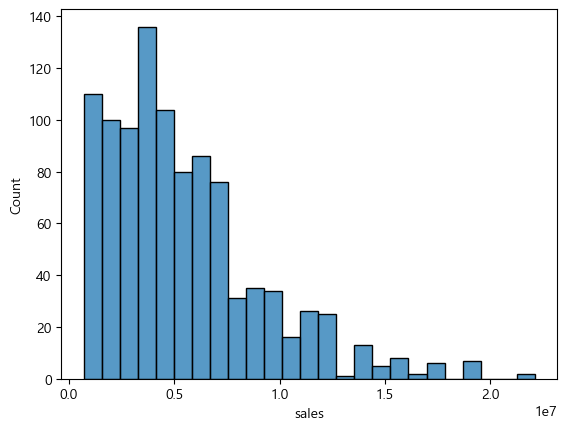

In [17]:
sns.histplot(data=df1, x='sales')
# sns.histplot(data=df1, x='sales', hue='category' , kde=True)

<Axes: xlabel='sales', ylabel='Density'>

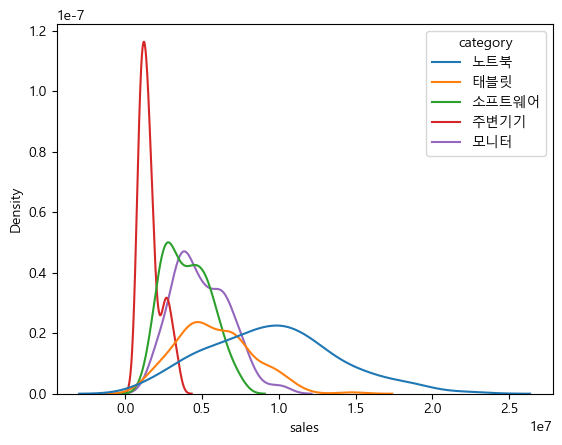

In [18]:
# 히스토그램과 비슷하나 밀도 기반으로 시각화
sns.kdeplot(data = df1, x='sales', hue='category')

### 스캐터플랏(scatterplot)
   - 두개의 컬럼을 사용

<Axes: xlabel='sales', ylabel='discount'>

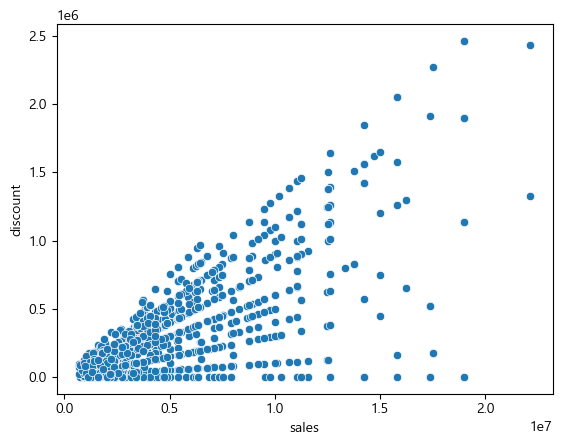

In [20]:
sns.scatterplot(data=df1, x='sales', y='discount')

### 박스플롯

<Axes: xlabel='cost'>

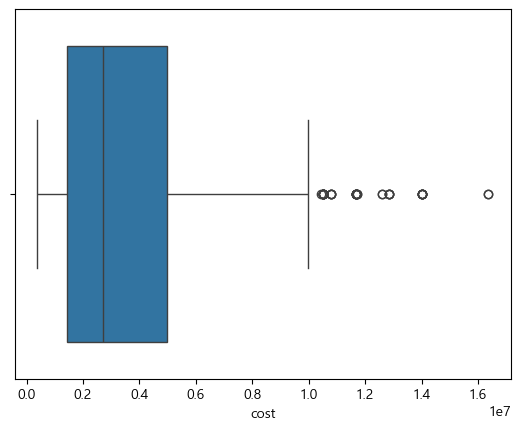

In [22]:
sns.boxplot(data=df1, x='cost')

<Axes: xlabel='transaction_date', ylabel='매출액'>

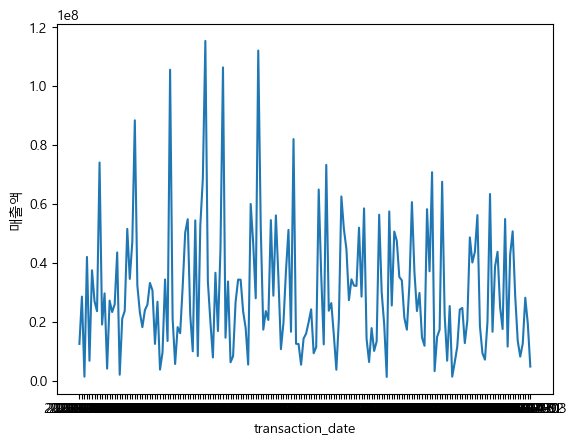

In [23]:
df1_grouped = df1.groupby('transaction_date').agg(
    매출액=('sales','sum')
).sort_values(by='transaction_date')
sns.lineplot(data = df1_grouped, x='transaction_date', y='매출액')

### 카테고리별 매출액은?

In [25]:
# 어떤 카테고리 매출이 가장 큰가?
result = df1.groupby('category').agg(
    매출액 = ('sales', 'sum'),
    판매수량 = ('quantity', 'sum'),
    평균매출 = ('sales', 'mean'),
    판매건수 = ('sales', 'count')
).sort_values('매출액', ascending=False).reset_index()

In [26]:
result

,category,매출액,판매수량,평균매출,판매건수
0,노트북,2364590000,1933,9.573239e+06,247
1,모니터,1102510000,2149,4.943991e+06,223
2,태블릿,894240000,1128,5.806753e+06,154
3,소프트웨어,856640000,2370,4.021784e+06,213
4,주변기기,264364000,2826,1.621865e+06,163


<Axes: xlabel='category', ylabel='매출액'>

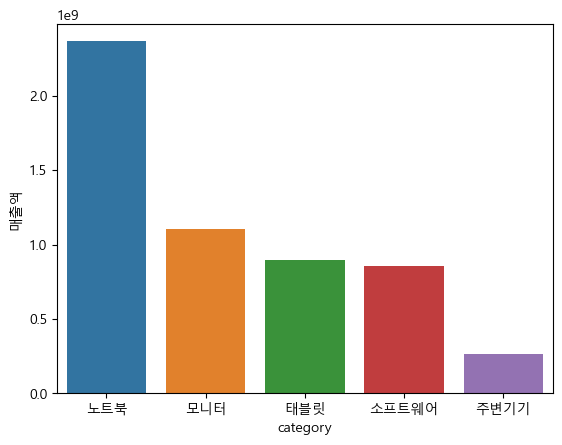

In [27]:
sns.barplot(data=result, x='category', hue='category', y='매출액')

### 고객유형별(customer_type) 매출액은?

In [29]:
# 어떤 카테고리 매출이 가장 큰가?
result = df1.groupby('customer_type').agg(
    매출액 = ('sales', 'sum'),
    판매수량 = ('quantity', 'sum'),
    평균매출 = ('sales', 'mean'),
    판매건수 = ('sales', 'count')
).sort_values('매출액', ascending=False).reset_index()

In [30]:
result

,customer_type,매출액,판매수량,평균매출,판매건수
0,공공기관,1439443000,1967,8.272661e+06,174
1,대기업,1352925000,2132,7.516250e+06,180
2,중소기업,995350000,1767,4.463453e+06,223
3,개인,889248000,2541,4.079119e+06,218
4,소상공인,805378000,1999,3.928673e+06,205


<Axes: xlabel='customer_type', ylabel='매출액'>

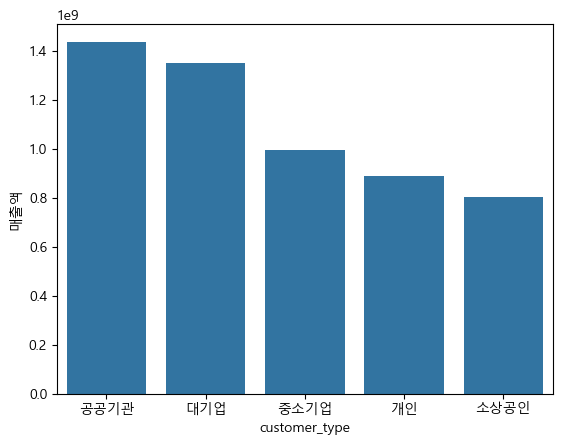

In [31]:
sns.barplot(data=result, x='customer_type', y='매출액', legend=True)

### 상품과 고객유형을 결합하여 분석할 수 있을까?

In [33]:
# 어떤 카테고리 매출이 가장 큰가?
result = df1.groupby(['category', 'customer_type']).agg(
    매출액 = ('sales', 'sum'),
    판매수량 = ('quantity', 'sum'),
    평균매출 = ('sales', 'mean'),
    판매건수 = ('sales', 'count')
).sort_values('매출액', ascending=False).reset_index()

In [34]:
result.head()

,category,customer_type,매출액,판매수량,평균매출,판매건수
0,노트북,공공기관,977290000,764,1.237076e+07,79
1,노트북,대기업,846390000,702,1.113671e+07,76
2,노트북,중소기업,399660000,345,5.474795e+06,73
3,모니터,중소기업,381530000,737,4.829494e+06,79
4,태블릿,개인,360440000,445,5.813548e+06,62


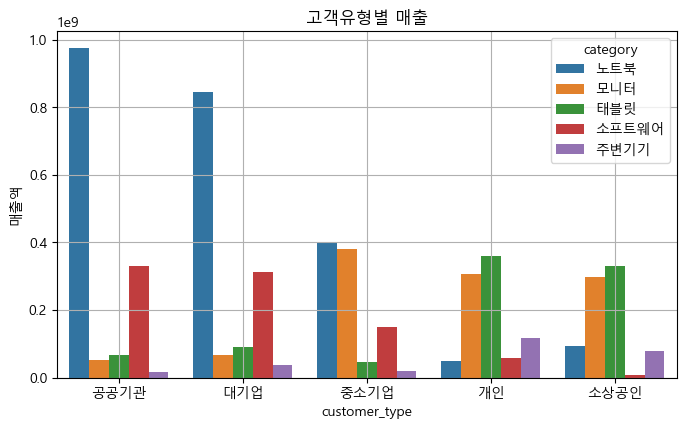

In [35]:

plt.figure(figsize = (8,4.5))
sns.barplot(data=result, 
            x='customer_type', 
            y='매출액', 
            hue='category', 
            legend=True)
plt.title('고객유형별 매출')
plt.grid(True)


### df1을 이용해서 그리는 방법

<Axes: xlabel='category', ylabel='net_sales'>

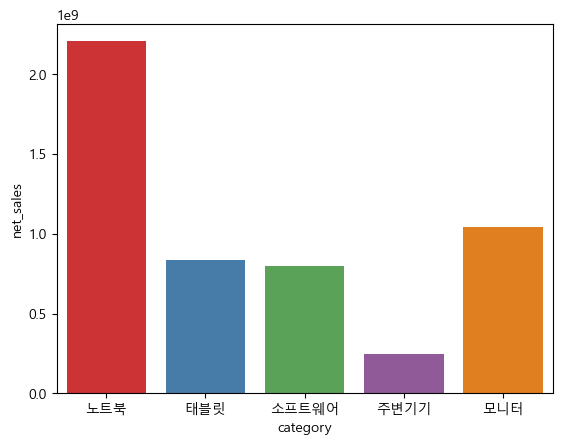

In [37]:
sns.barplot(data=df1,
            x='category',
            y='net_sales',
            estimator='sum',   # groupby효과
            errorbar=None,
            hue='category',
            palette='Set1')

### 일자별 매출현황

<Axes: xlabel='요일no', ylabel='매출액'>

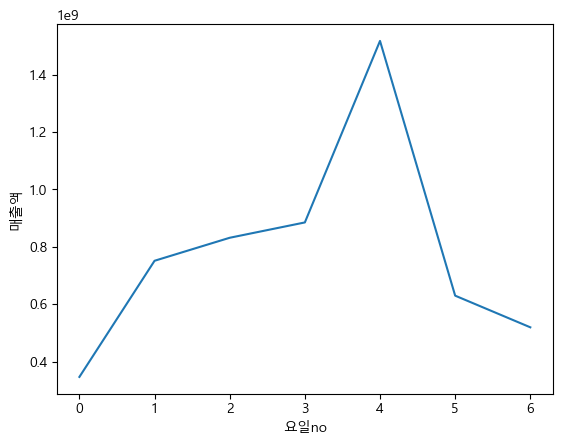

In [39]:
# 요일별 현황
## 요일 파생변수 만들기
df1['transaction_date'] = pd.to_datetime(df1['transaction_date'])
df1['요일no'] = df1['transaction_date'].dt.dayofweek
df1['요일'] = df1['transaction_date'].dt.day_name()
## groupby
df1_grouped = df1.groupby(['요일no','요일']).agg(
    매출액 = ('sales', 'sum')
)
## chart
sns.lineplot(data = df1_grouped, x='요일no', y='매출액', legend=True)

In [79]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   transaction_id    1000 non-null   object        
 1   transaction_date  1000 non-null   datetime64[ns]
 2   employee_id       1000 non-null   object        
 3   customer_type     1000 non-null   object        
 4   product_name      1000 non-null   object        
 5   category          1000 non-null   object        
 6   unit_price        1000 non-null   int64         
 7   quantity          1000 non-null   int64         
 8   discount_rate     1000 non-null   float64       
 9   unit_cost         1000 non-null   int64         
 10  sales             1000 non-null   int64         
 11  discount          1000 non-null   float64       
 12  net_sales         1000 non-null   float64       
 13  cost              1000 non-null   int64         
 14  요일no              1000 no

<Axes: xlabel='transaction_date', ylabel='매출액'>

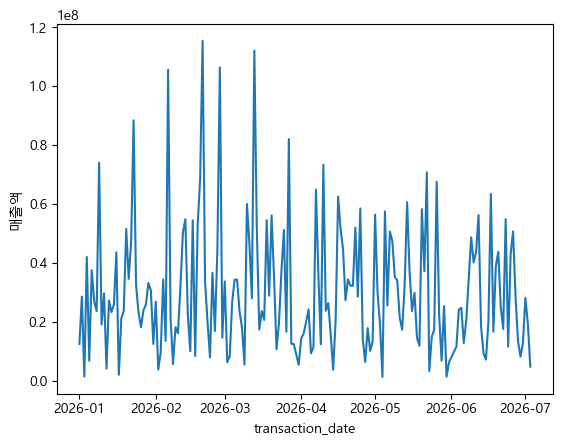

In [87]:
## groupby
df1_grouped = df1.groupby(['transaction_date']).agg(
    매출액 = ('sales', 'sum')
)
## chart
sns.lineplot(data = df1_grouped, x='transaction_date', y='매출액', legend=True)

### 히트맵

<Axes: >

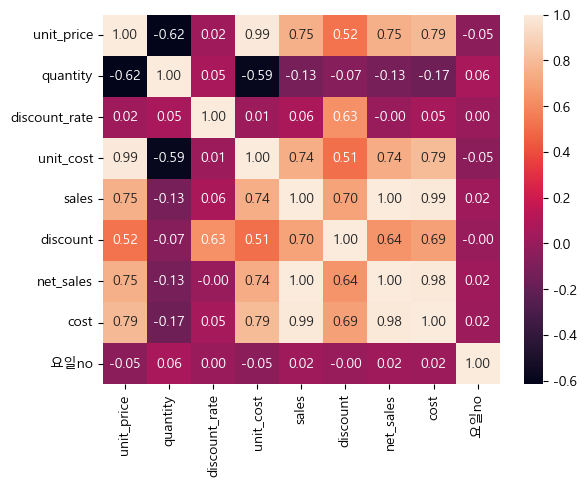

In [40]:
corr = df1.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f')

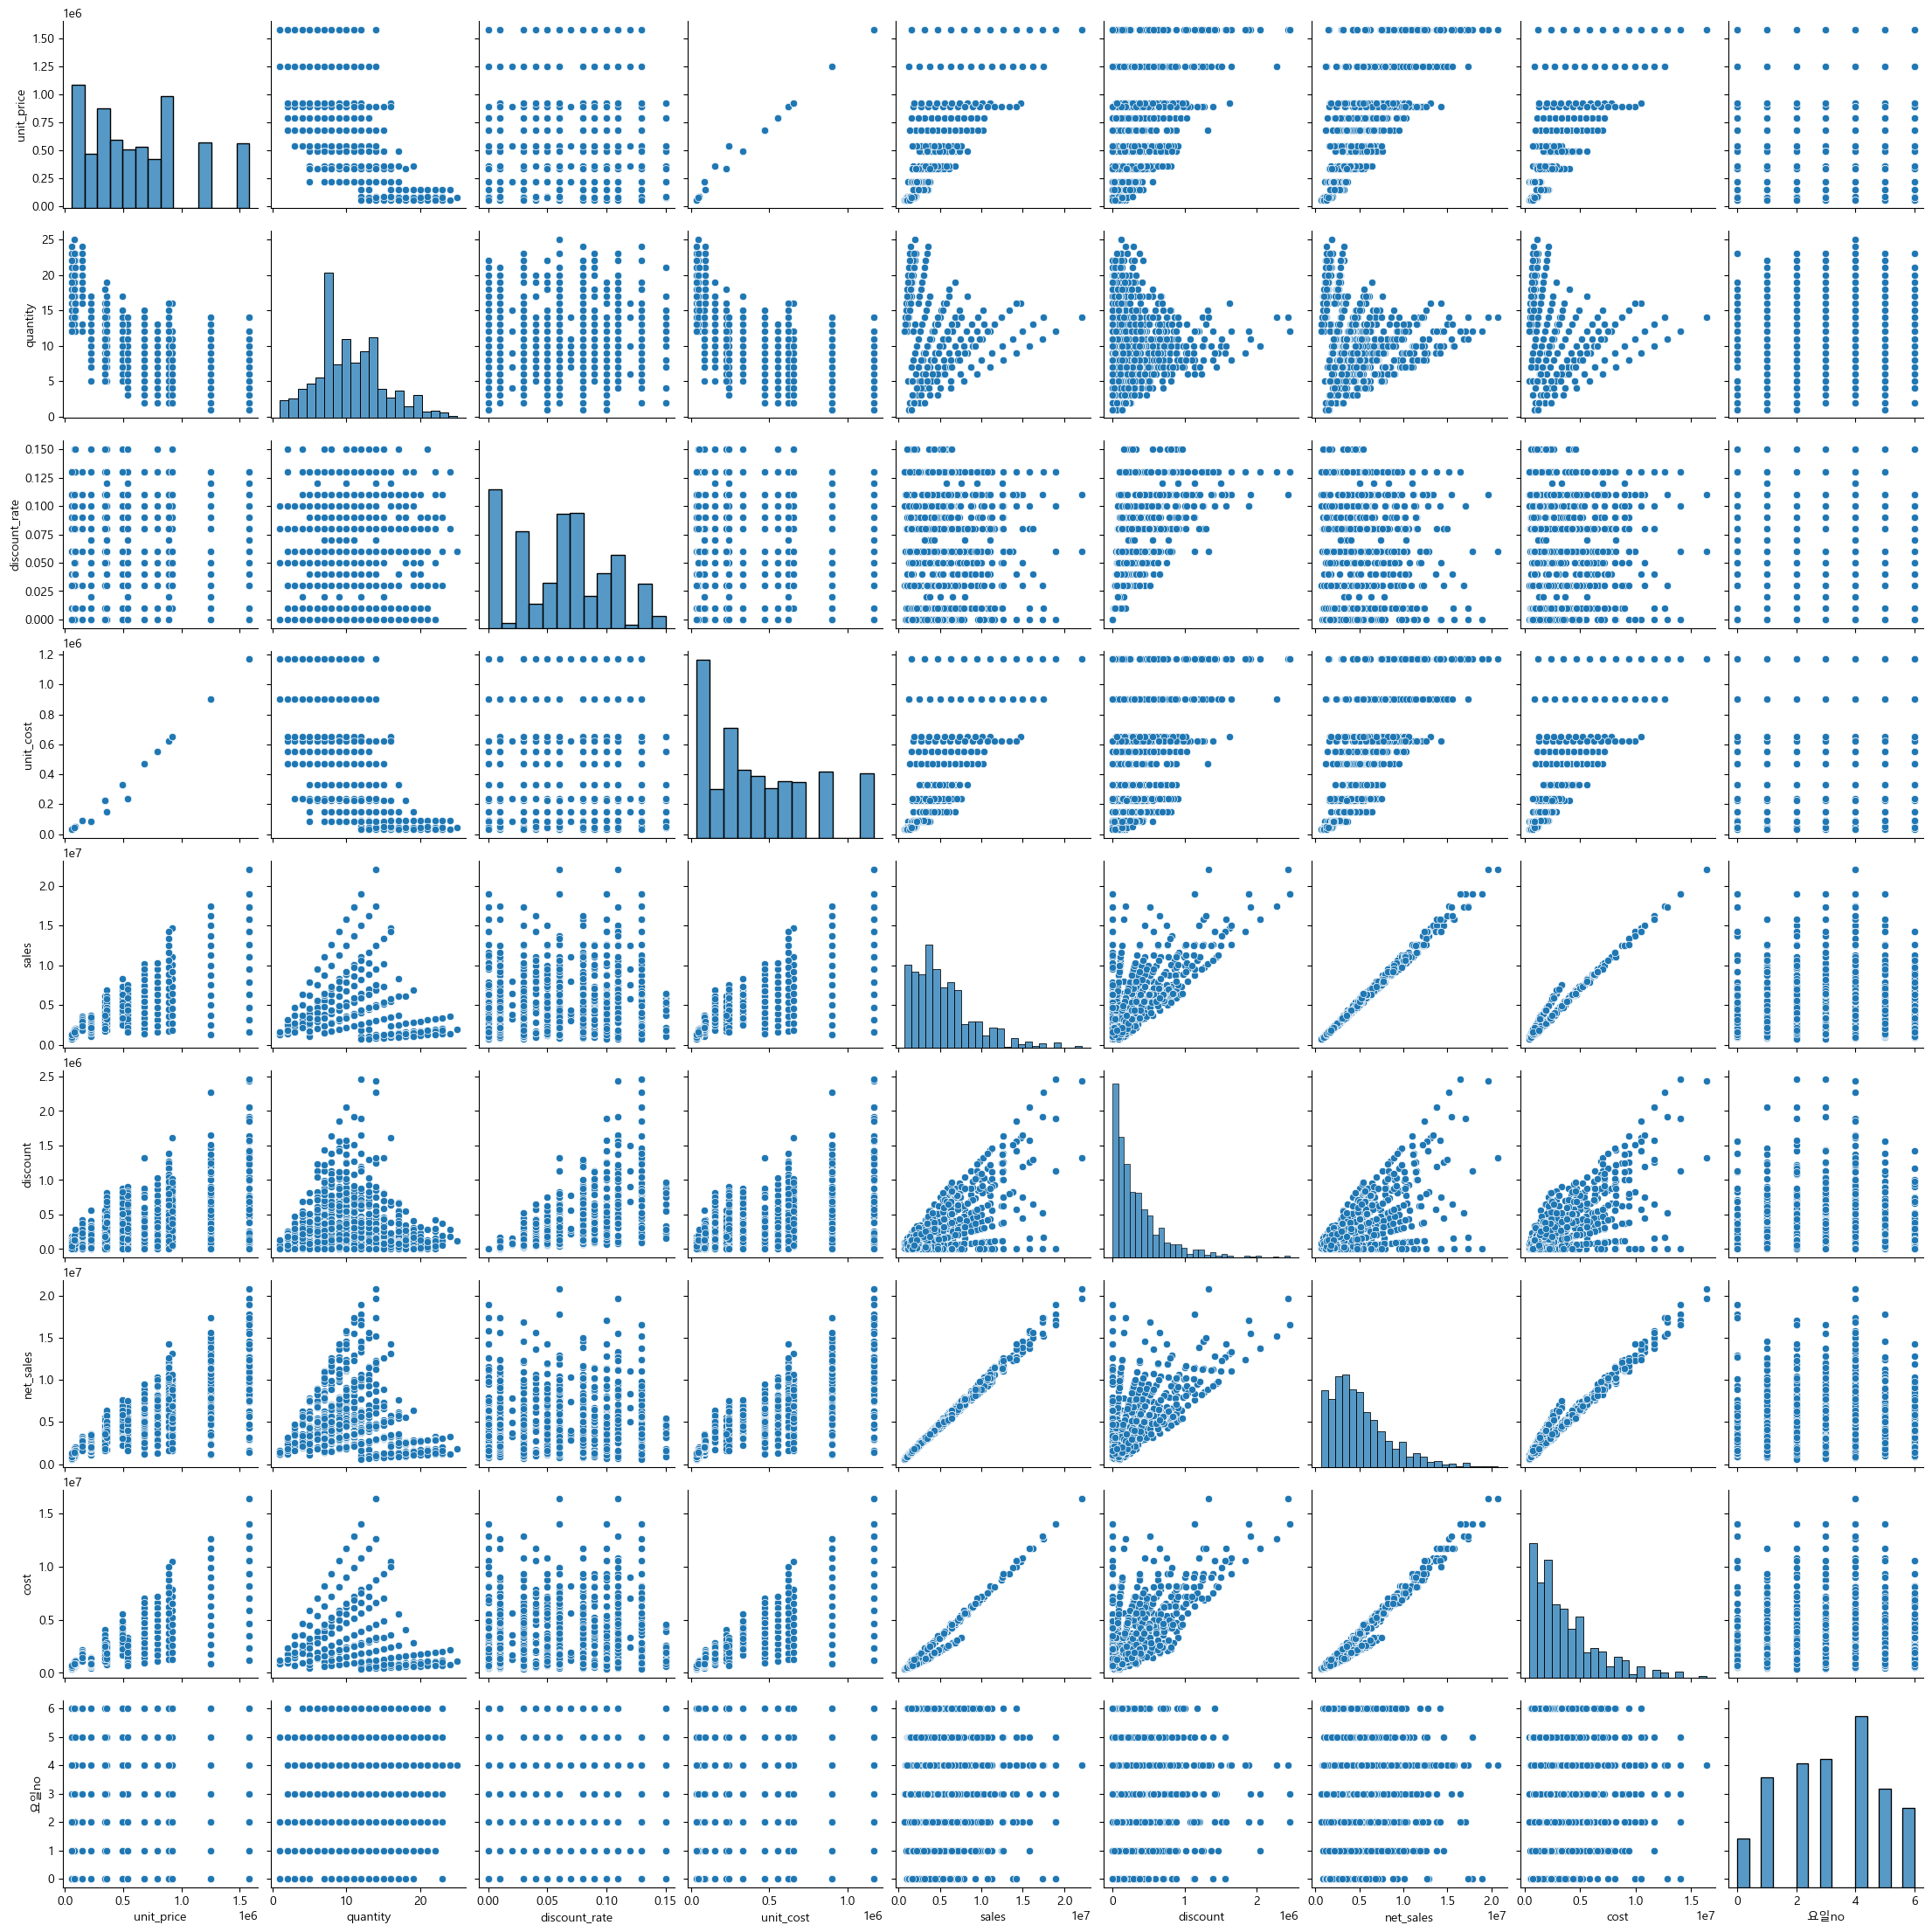

In [90]:
# 페어플롯
sns.pairplot(data=df1)